# Workshop #1 — Source Profiling
**Team 7 — Landslide Monitoring and Risk (Colombia)**

This notebook profiles the four data sources with the raw samples collected on 2026-11-07 (UTC).
All inputs are read from `workshop_1/samples/` (committed evidence).

| # | Source | Role | Sample used here |
|---|---|---|---|
| 1 | NASA Global Landslide Catalog (GLC) | Historical | Full export, 11,033 events (unmodified file) |
| 2 | Open-Meteo Historical Weather API (ERA5) | Historical | 10 cities × 731 days (unmodified) + 15-day windows before 107 landslides (response wrapped with its request) |
| 3 | Open-Meteo Forecast API | Incremental | Three polls of 10 cities × 240 hours (04:47, 05:58 and 13:04 UTC), unmodified |
| 4 | NASA LHASA nowcast | Incremental | Directory listings at 04:59, 05:58 and 13:04 UTC (unmodified), HEAD headers, raster metadata, and the Colombia window of two daily rasters (derived: clipped and flipped north-up) |

Run it from the repository root: `jupyter nbconvert --to notebook --execute --inplace notebooks/01_source_profiling.ipynb`

In [1]:
import glob, json, os, re, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio

ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SAMPLES = ROOT / "workshop_1" / "samples"
RAW = ROOT / "data" / "raw"
pd.set_option("display.max_colwidth", 60)
CO_BBOX = dict(lat=(-4.3, 13.5), lon=(-79.1, -66.8))

def haversine_km(lat1, lon1, lat2, lon2):
    p = np.radians
    a = np.sin(p(lat2 - lat1) / 2) ** 2 + np.cos(p(lat1)) * np.cos(p(lat2)) * np.sin(p(lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))

def null_report(df):
    return (df.isna().mean() * 100).round(1).sort_values(ascending=False).rename("null_%").to_frame()

## 1. NASA Global Landslide Catalog (historical)
Static CSV export. The download URL redirects to a pre-signed Amazon S3 link (see the saved headers).

In [2]:
print(open(SAMPLES / "nasa_glc_20261107_045852.headers").read())

HTTP/1.1 200 Connection Established

HTTP/2 302 
date: Sat, 07 Nov 2026 04:58:53 GMT
content-length: 0
location: https://data-nasa-bucket-production.s3.us-east-1.amazonaws.com/legacy/Global_Landslide_Catalog_Export/Global_Landslide_Catalog_Export_rows.csv?[pre-signed query string removed: contains temporary credentials]
access-control-allow-credentials: true
content-security-policy: default-src 'self';base-uri 'self';font-src 'self' https: data:;form-action 'self';frame-ancestors 'self';img-src 'self' data:;object-src 'none';script-src 'self';script-src-attr 'none';style-src 'self' https: 'unsafe-inline';upgrade-insecure-requests
cross-origin-opener-policy: same-origin
cross-origin-resource-policy: cross-origin
origin-agent-cluster: ?1
referrer-policy: strict-origin-when-cross-origin
strict-transport-security: max-age=31536000; includeSubDomains; preload
vary: Origin
x-content-type-options: nosniff
x-dns-prefetch-control: off
x-download-options: noopen
x-frame-options: SAMEORIGIN
x-per

In [3]:
glc_file = SAMPLES / "nasa_glc_20261107_045852.csv"   # full export, unmodified
glc = pd.read_csv(glc_file)
print(glc_file.name, glc.shape)
glc.head(3).T

nasa_glc_20261107_045852.csv (11033, 31)


,0,1,2
source_name,AGU,Oregonian,CBS News
source_link,https://blogs.agu.org/landslideblog/2008/10/14/the-lifan...,http://www.oregonlive.com/news/index.ssf/2009/01/landsli...,https://www.cbsnews.com/news/dozens-missing-after-peru-l...
event_id,684,956,973
event_date,08/01/2008 12:00:00 AM,01/02/2009 02:00:00 AM,01/19/2007 12:00:00 AM
event_time,NaN,NaN,NaN
event_title,"Sigou Village, Loufan County, Shanxi Province","Lake Oswego, Oregon","San Ramon district, 195 miles northeast of the capital, ..."
event_description,"occurred early in morning, 11 villagers buried in 7 houses",Hours of heavy rain are to blame for an overnight mudsli...,(CBS/AP) At least 10 people died and as many as 80 were ...
location_description,"Sigou Village, Loufan County, Shanxi Province","Lake Oswego, Oregon","San Ramon district, 195 miles northeast of the capital, ..."
location_accuracy,unknown,5km,10km
landslide_category,landslide,mudslide,landslide


In [4]:
print(null_report(glc).to_string())

                           null_%
event_time                  100.0
notes                        97.1
storm_name                   94.8
photo_link                   86.4
injury_count                 51.4
admin_division_name          14.8
event_import_source          14.2
country_code                 14.2
country_name                 14.2
event_import_id              14.2
admin_division_population    14.2
gazeteer_closest_point       14.2
gazeteer_distance            14.2
fatality_count               12.6
event_description             7.8
source_link                   7.7
location_description          0.9
landslide_setting             0.6
landslide_trigger             0.2
landslide_size                0.1
submitted_date                0.1
event_id                      0.0
source_name                   0.0
location_accuracy             0.0
landslide_category            0.0
event_date                    0.0
event_title                   0.0
created_date                  0.0
last_edited_da

### Identifiers, timestamps and time zone

In [5]:
print("duplicated event_id:", glc.event_id.duplicated().sum())
print("event_time non-null:", glc.event_time.notna().sum())
print("event_date examples:", glc.event_date.head(3).tolist())
glc["event_dt"] = pd.to_datetime(glc.event_date, format="%m/%d/%Y %I:%M:%S %p")
print("range:", glc.event_dt.min(), "→", glc.event_dt.max())
print("share of events at exactly 00:00 (time unknown):",
      round((glc.event_dt.dt.strftime("%H:%M") == "00:00").mean() * 100, 1), "%")

duplicated event_id: 0
event_time non-null: 0
event_date examples: ['08/01/2008 12:00:00 AM', '01/02/2009 02:00:00 AM', '01/19/2007 12:00:00 AM']


range: 1988-11-07 00:00:00 → 2017-09-28 19:36:00
share of events at exactly 00:00 (time unknown): 50.1 %


The date has no time-zone information. The catalog is compiled from news reports, so times are
local to the event. For Colombia this means UTC−05:00 (no daylight saving time).

### Coordinates and categorical fields

In [6]:
print("lat range:", glc.latitude.min(), glc.latitude.max(), "| lon range:", glc.longitude.min(), glc.longitude.max())
print("out-of-range coordinates:", (~glc.latitude.between(-90, 90) | ~glc.longitude.between(-180, 180)).sum())
print("(0,0) coordinates:", ((glc.latitude == 0) & (glc.longitude == 0)).sum())
for col in ["location_accuracy", "landslide_category", "landslide_trigger", "landslide_size"]:
    print("\n", glc[col].value_counts(dropna=False).head(10).to_string())

lat range: -46.7748 72.6275 | lon range: -179.9807656 179.991364
out-of-range coordinates: 0
(0,0) coordinates: 0

 location_accuracy
5km        3178
1km        2185
25km       1470
10km       1435
exact      1386
50km        794
unknown     542
100km        25
250km        16
NaN           2

 landslide_category
landslide              7648
mudslide               2100
rock_fall               671
complex                 232
debris_flow             194
other                    68
unknown                  38
riverbank_collapse       37
snow_avalanche           15
translational_slide       9

 landslide_trigger
downpour             4680
rain                 2592
unknown              1691
continuous_rain       748
tropical_cyclone      561
snowfall_snowmelt     135
monsoon               129
mining                 93
earthquake             89
construction           82

 landslide_size
medium          6551
small           2767
unknown          851
large            750
very_large       102
NaN

In [7]:
glc.fatality_count.describe()

count    9648.000000
mean        3.219424
std        59.886178
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max      5000.000000
Name: fatality_count, dtype: float64

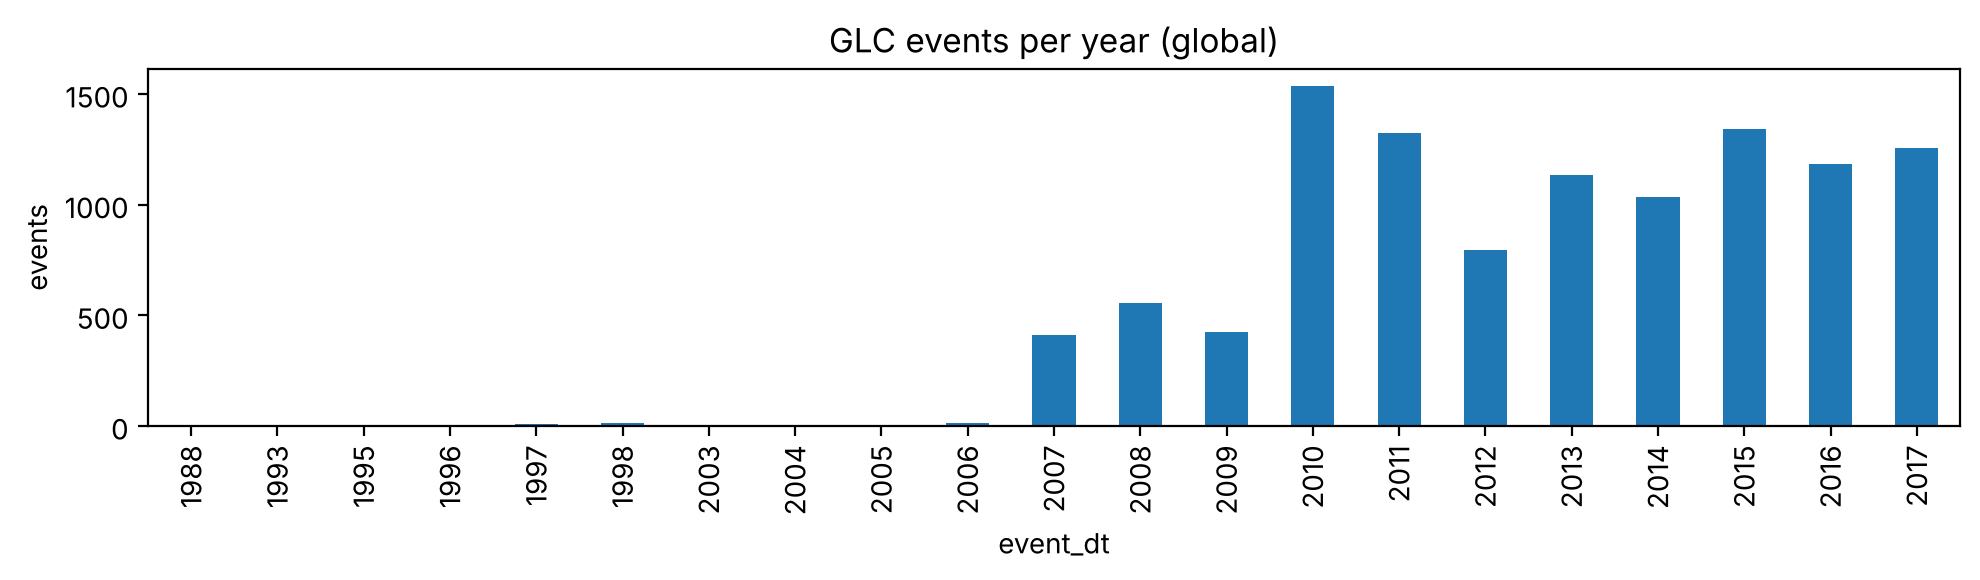

In [8]:
ax = glc.event_dt.dt.year.value_counts().sort_index().plot.bar(figsize=(10, 3), title="GLC events per year (global)")
ax.set_ylabel("events"); plt.tight_layout(); plt.show()

### Colombian subset
`country_name` is empty for 14.2 % of the rows, so filtering by country loses events. The subset is built
with the Colombia bounding box and then checked event by event.

In [9]:
in_bbox = glc.latitude.between(*CO_BBOX["lat"]) & glc.longitude.between(*CO_BBOX["lon"])
print(glc[in_bbox].country_name.value_counts(dropna=False).to_string())
glc[in_bbox & glc.country_name.isna()][["event_id", "event_date", "event_title", "latitude", "longitude", "source_name"]]

country_name
Colombia     101
Ecuador       21
Venezuela     19
NaN            8
Panama         1


,event_id,event_date,event_title,latitude,longitude,source_name
10153,10792,11/08/2016 03:00:00 PM,Landslide in EL Tambo,2.452671,-76.810198,The New Indian Express
10190,10790,03/25/2017 05:32:00 PM,Deadly Mocoa Landslide,1.151898,-76.639923,BBC News
10234,10793,04/19/2017 01:35:00 PM,"Fatal landslide in Manizales, various other slides throu...",5.076694,-75.497428,Noticias Caracol
10412,10794,02/22/2017 02:46:00 PM,Gachetá Landslide near the Amoladero River,4.815959,-73.642328,Prensa Latina
10439,10789,02/21/2017 08:51:00 PM,Molleturo Landslide on Highway 35,-0.375034,-78.492061,Cuenca High Life
10799,10791,12/01/2016 03:24:00 PM,Hillside Wall Collapse Destroys Cali Houses,3.423928,-76.553491,Colombia Reports
10845,10795,10/26/2016 02:24:00 PM,Mudslide kills at least 7 on Colombian highway,6.358246,-75.499849,CBC News
11009,10788,02/21/2017 08:51:00 PM,Two Landslides Between Cuenca and Guayaquil on Highway 35,-2.618694,-78.915769,Cuenca High Life


Six of the eight events without a country are Colombian (El Tambo, Mocoa, Manizales, Gachetá, Cali,
Medellín–Quibdó highway); events 10788 and 10789 are in Ecuador.

In [10]:
ECUADOR_NO_COUNTRY = [10788, 10789]
co = glc[in_bbox & (glc.country_name.eq("Colombia") | glc.country_name.isna())
         & ~glc.event_id.isin(ECUADOR_NO_COUNTRY)].copy().reset_index(drop=True)
print("Colombian events:", len(co), "| range:", co.event_dt.min().date(), "→", co.event_dt.max().date())
print(co.event_dt.dt.year.value_counts().sort_index().to_string())

Colombian events: 107 | range: 2007-05-21 → 2017-04-19
event_dt
2007     3
2008     9
2009     2
2010    23
2011    39
2012     5
2013     2
2014     8
2015     4
2016     9
2017     3


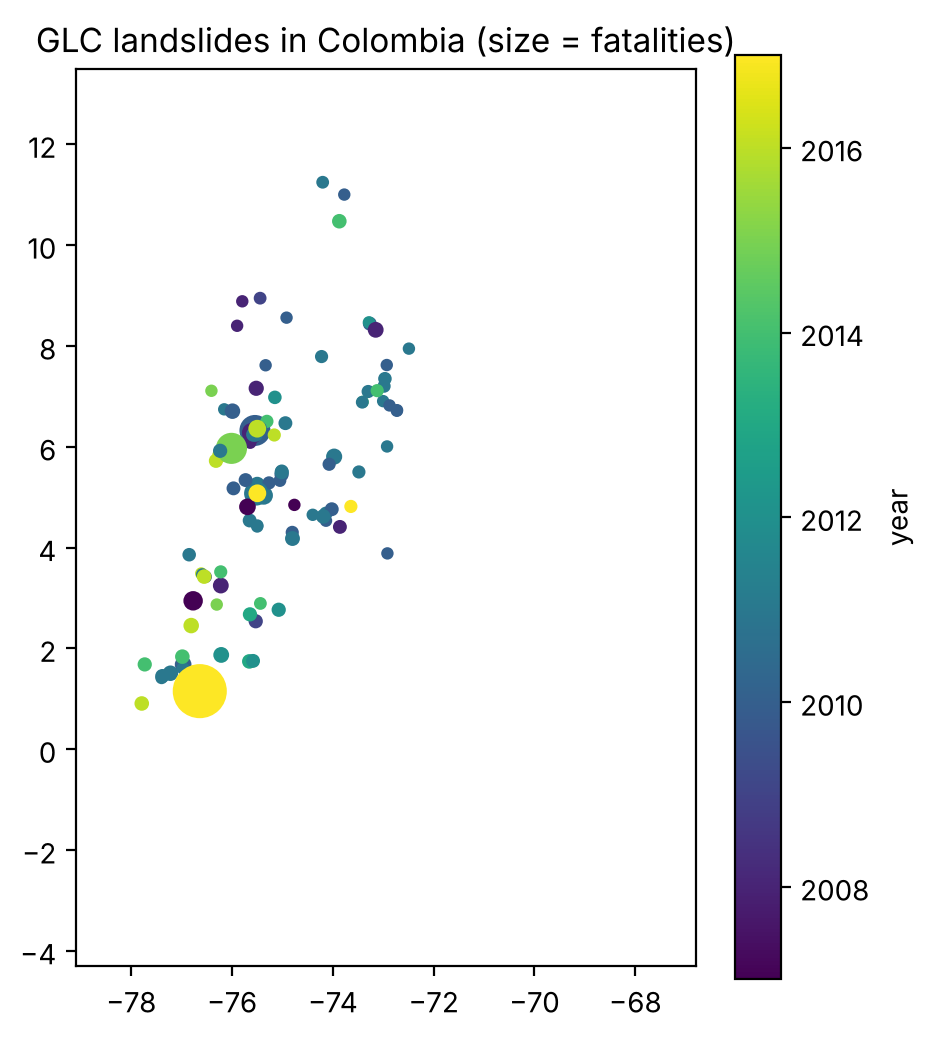

In [11]:
fig, ax = plt.subplots(figsize=(5, 6))
sc = ax.scatter(co.longitude, co.latitude, c=co.event_dt.dt.year, s=12 + co.fatality_count.fillna(0), cmap="viridis")
ax.set_xlim(*CO_BBOX["lon"]); ax.set_ylim(*CO_BBOX["lat"]); ax.set_aspect("equal")
ax.set_title("GLC landslides in Colombia (size = fatalities)"); plt.colorbar(sc, label="year"); plt.show()

## 2. Open-Meteo Historical Weather API (historical)
Request: 10 Andean cities, daily precipitation, 2016-01-01 → 2017-12-31, UTC.

In [12]:
print(open(SAMPLES / "openmeteo_historical_20261107_044802.url").read())
hist_raw = json.load(open(SAMPLES / "openmeteo_historical_20261107_044802.json"))
cities = pd.DataFrame([
    ("Bogota", 4.711, -74.072), ("Medellin", 6.244, -75.581), ("Manizales", 5.070, -75.517),
    ("Mocoa", 1.152, -76.646), ("Cali", 3.452, -76.532), ("Bucaramanga", 7.119, -73.123),
    ("Pasto", 1.214, -77.281), ("Ibague", 4.438, -75.232), ("Popayan", 2.444, -76.614),
    ("Pereira", 4.813, -75.696)], columns=["city", "req_lat", "req_lon"])
frames = []
for city, loc in zip(cities.city, hist_raw):
    f = pd.DataFrame(loc["daily"]); f["city"] = city
    f["grid_lat"], f["grid_lon"], f["elevation_m"] = loc["latitude"], loc["longitude"], loc["elevation"]
    frames.append(f)
hist = pd.concat(frames, ignore_index=True)
print(hist.shape, "| units:", hist_raw[0]["daily_units"], "| timezone:", hist_raw[0]["timezone"])
hist.head()

https://archive-api.open-meteo.com/v1/archive?latitude=4.711,6.244,5.070,1.152,3.452,7.119,1.214,4.438,2.444,4.813&longitude=-74.072,-75.581,-75.517,-76.646,-76.532,-73.123,-77.281,-75.232,-76.614,-75.696&start_date=2016-01-01&end_date=2017-12-31&daily=precipitation_sum,rain_sum,precipitation_hours&timezone=UTC

(7310, 8) | units: {'time': 'iso8601', 'precipitation_sum': 'mm', 'rain_sum': 'mm', 'precipitation_hours': 'h'} | timezone: GMT


,time,precipitation_sum,rain_sum,precipitation_hours,city,grid_lat,grid_lon,elevation_m
0,2016-01-01,0.0,0.0,0.0,Bogota,4.745167,-74.10025,2557.0
1,2016-01-02,1.4,1.4,7.0,Bogota,4.745167,-74.10025,2557.0
2,2016-01-03,0.7,0.7,5.0,Bogota,4.745167,-74.10025,2557.0
3,2016-01-04,2.7,2.7,10.0,Bogota,4.745167,-74.10025,2557.0
4,2016-01-05,2.7,2.7,8.0,Bogota,4.745167,-74.10025,2557.0


In [13]:
print(null_report(hist).T)
print("duplicated (city, date):", hist.duplicated(["city", "time"]).sum())
hist.groupby("city").precipitation_sum.describe().round(1)

        time  precipitation_sum  rain_sum  precipitation_hours  city  \
null_%   0.0                0.0       0.0                  0.0   0.0   

        grid_lat  grid_lon  elevation_m  
null_%       0.0       0.0          0.0  
duplicated (city, date): 0


,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Bogota,731.0,3.2,5.2,0.0,0.2,1.1,4.0,41.0
Bucaramanga,731.0,14.0,17.4,0.0,3.2,8.3,18.8,175.6
Cali,731.0,9.1,12.2,0.0,1.1,4.6,13.0,93.6
Ibague,731.0,7.4,9.5,0.0,0.3,3.2,11.0,49.3
Manizales,731.0,30.2,28.0,0.0,7.9,21.3,46.0,161.5
Medellin,731.0,6.5,6.9,0.0,1.3,4.8,9.6,70.0
Mocoa,731.0,8.3,13.5,0.0,0.6,3.2,9.9,105.2
Pasto,731.0,8.0,8.9,0.0,1.5,4.5,11.8,56.4
Pereira,731.0,23.5,24.4,0.0,4.3,13.9,37.2,125.7


In [14]:
print("days with precipitation_sum != rain_sum:", (hist.precipitation_sum != hist.rain_sum).sum())
print("negative values:", (hist[["precipitation_sum", "rain_sum", "precipitation_hours"]] < 0).sum().sum())

days with precipitation_sum != rain_sum: 0
negative values: 0


### Grid snapping: requested point vs. returned grid cell

In [15]:
snap = hist.drop_duplicates("city").merge(cities, on="city")
snap["offset_km"] = haversine_km(snap.req_lat, snap.req_lon, snap.grid_lat, snap.grid_lon).round(2)
snap[["city", "req_lat", "req_lon", "grid_lat", "grid_lon", "offset_km", "elevation_m"]]

,city,req_lat,req_lon,grid_lat,grid_lon,offset_km,elevation_m
0,Bogota,4.711,-74.072,4.745167,-74.100250,4.92,2557.0
1,Medellin,6.244,-75.581,6.221441,-75.551850,4.08,1479.0
2,Manizales,5.070,-75.517,5.096661,-75.519806,2.98,2096.0
3,Mocoa,1.152,-76.646,1.089631,-76.595730,8.91,597.0
4,Cali,3.452,-76.532,3.479789,-76.518220,3.45,1011.0
5,Bucaramanga,7.119,-73.123,7.135325,-73.110750,2.26,964.0
6,Pasto,1.214,-77.281,1.300527,-77.345950,12.03,2546.0
7,Ibague,4.438,-75.232,4.393673,-75.196380,6.32,1231.0
8,Popayan,2.444,-76.614,2.495606,-76.597260,6.03,1728.0
9,Pereira,4.813,-75.696,4.815466,-75.715454,2.17,1410.0


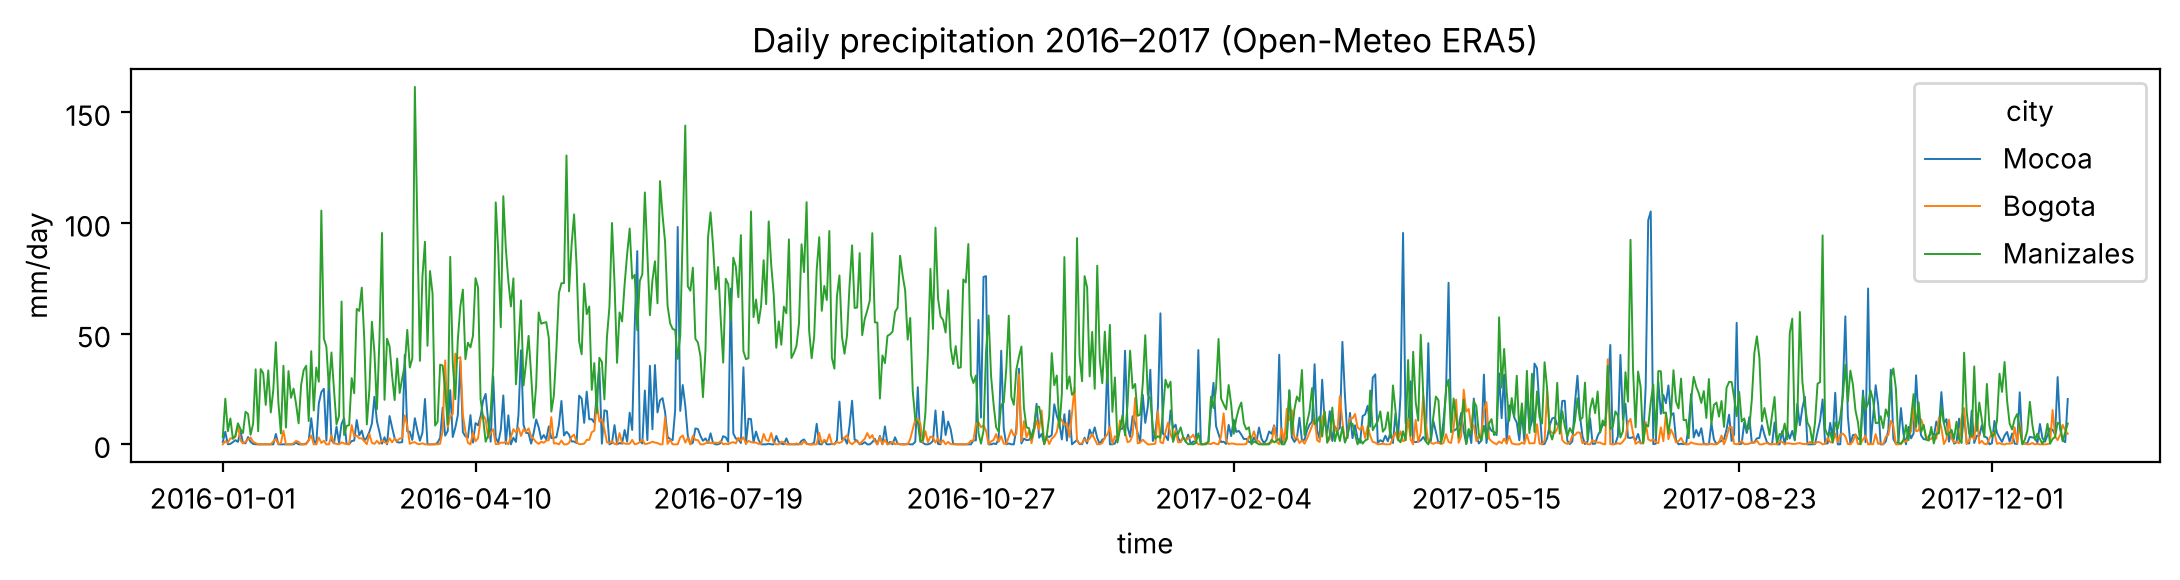

In [16]:
ax = hist.pivot(index="time", columns="city", values="precipitation_sum")[["Mocoa", "Bogota", "Manizales"]].plot(
    figsize=(11, 3), lw=0.7, title="Daily precipitation 2016–2017 (Open-Meteo ERA5)")
ax.set_ylabel("mm/day"); plt.tight_layout(); plt.show()

### Antecedent rainfall before each Colombian landslide
For each of the 107 Colombian GLC events, Open-Meteo was queried at the event coordinates from 14 days before the event date up to and
including the event date (15 daily values; `rain_15d` below is that 15-day sum) (`timezone=America/Bogota`). 107 requests, all HTTP 200.

In [17]:
ev_rows = []
for fp in sorted((SAMPLES / "openmeteo_events").glob("glc_*.json")):
    j = json.load(open(fp)); d = j["response"]["daily"]
    p = np.array(d["precipitation_sum"], dtype=float)
    ev_rows.append(dict(event_id=j["event_id"], grid_lat=j["response"]["latitude"], grid_lon=j["response"]["longitude"],
                        n_days=len(p), nulls=int(np.isnan(p).sum()), rain_event_day=p[-1], rain_3d=p[-3:].sum(),
                        rain_7d=p[-7:].sum(), rain_15d=p.sum()))
ante = co.merge(pd.DataFrame(ev_rows), on="event_id")
ante["snap_km"] = haversine_km(ante.latitude, ante.longitude, ante.grid_lat, ante.grid_lon).round(1)
print(len(ante), "events | daily records:", ante.n_days.sum(), "| nulls:", ante.nulls.sum())
ante[["rain_event_day", "rain_3d", "rain_7d", "rain_15d", "snap_km"]].describe().round(1)

107 events | daily records: 1605 | nulls: 0


,rain_event_day,rain_3d,rain_7d,rain_15d,snap_km
count,107.0,107.0,107.0,107.0,107.0
mean,16.7,50.9,119.2,243.3,4.7
std,14.0,37.2,82.1,160.7,3.0
min,0.0,0.4,4.9,36.1,0.1
25%,7.2,23.2,66.8,155.6,2.5
50%,14.1,46.5,101.5,206.9,4.1
75%,22.0,59.6,143.9,299.4,6.4
max,74.9,190.4,616.5,1235.1,14.1


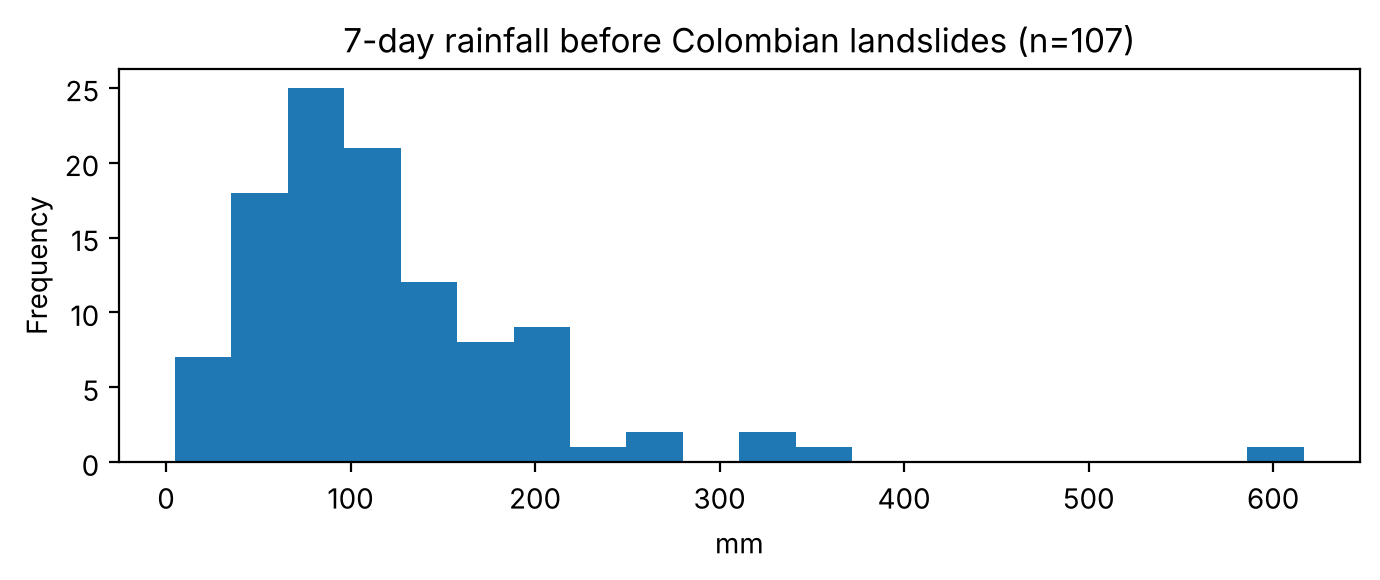

events with < 5 mm in the previous 7 days: 1


,event_id,event_date,event_title,landslide_trigger,location_accuracy,rain_7d
78,4121,12/30/2011 12:00:00 AM,"Samaná, Caldas",downpour,25km,4.9
74,605,06/24/2008 12:00:00 AM,"Hacari, North Santander",downpour,5km,17.7
62,4637,11/28/2012 12:00:00 AM,"Teorama , Norte de Santander",rain,10km,18.5
44,5192,07/25/2013 03:30:00 PM,"The Mine Called La Milagrosa, Iquira, Huila",rain,25km,22.2
82,397,12/19/2007 12:00:00 AM,highway connecting Bogota and Manizales,rain,unknown,23.9


In [18]:
ax = ante.rain_7d.plot.hist(bins=20, figsize=(7, 3), title="7-day rainfall before Colombian landslides (n=107)")
ax.set_xlabel("mm"); plt.tight_layout(); plt.show()
print("events with < 5 mm in the previous 7 days:", (ante.rain_7d < 5).sum())
ante.nsmallest(5, "rain_7d")[["event_id", "event_date", "event_title", "landslide_trigger", "location_accuracy", "rain_7d"]]

## 3. Open-Meteo Forecast API (incremental)
Same request polled three times: 2026-11-07 04:47:46, 05:58:36 (70 min later) and 13:04:05 UTC.
`past_days=7`, `forecast_days=3`, hourly precipitation, rain and soil moisture, `timezone=UTC`.

In [19]:
print(open(SAMPLES / "openmeteo_forecast_20261107_044746.url").read())
polls = {}
for fp in sorted(SAMPLES.glob("openmeteo_forecast_*.json")):
    ts = re.search(r"(\d{8}_\d{6})", fp.name).group(1)
    frames = []
    for city, loc in zip(cities.city, json.load(open(fp))):
        f = pd.DataFrame(loc["hourly"]); f["city"] = city
        f["current_time"], f["current_precip"] = loc["current"]["time"], loc["current"]["precipitation"]
        frames.append(f)
    polls[ts] = pd.concat(frames, ignore_index=True)
    print(ts, polls[ts].shape)
p1, p2 = list(polls.values())[:2]
print("units:", json.load(open(sorted(SAMPLES.glob("openmeteo_forecast_*.json"))[0]))[0]["hourly_units"])
print(null_report(p1).T)
print("time range:", p1.time.min(), "→", p1.time.max(), "| duplicated (city,time):", p1.duplicated(["city", "time"]).sum())

https://api.open-meteo.com/v1/forecast?latitude=4.711,6.244,5.070,1.152,3.452,7.119,1.214,4.438,2.444,4.813&longitude=-74.072,-75.581,-75.517,-76.646,-76.532,-73.123,-77.281,-75.232,-76.614,-75.696&hourly=precipitation,rain,soil_moisture_0_to_1cm&daily=precipitation_sum&current=precipitation,rain&past_days=7&forecast_days=3&timezone=UTC

20261107_044746 (2400, 7)
20261107_055836 (2400, 7)


20261107_130405 (2400, 7)
units: {'time': 'iso8601', 'precipitation': 'mm', 'rain': 'mm', 'soil_moisture_0_to_1cm': 'm³/m³'}
        time  precipitation  rain  soil_moisture_0_to_1cm  city  current_time  \
null_%   0.0            0.0   0.0                     0.0   0.0           0.0   

        current_precip  
null_%             0.0  
time range: 2026-10-31T00:00 → 2026-11-09T23:00 | duplicated (city,time): 0


### What changed between the two polls?

In [20]:
m = p1.merge(p2, on=["city", "time"], how="outer", suffixes=("_1", "_2"), indicator=True)
print(m._merge.value_counts().to_string())
both = m[m._merge == "both"]
changed = both[(both.precipitation_1 != both.precipitation_2) | (both.soil_moisture_0_to_1cm_1 != both.soil_moisture_0_to_1cm_2)]
print("hourly values changed:", len(changed))
cur = p1.drop_duplicates("city")[["city", "current_time", "current_precip"]].merge(
      p2.drop_duplicates("city")[["city", "current_time", "current_precip"]], on="city", suffixes=("_poll1", "_poll2"))
cur

_merge
both          2400
left_only        0
right_only       0
hourly values changed: 0


,city,current_time_poll1,current_precip_poll1,current_time_poll2,current_precip_poll2
0,Bogota,2026-11-07T04:45,0.0,2026-11-07T05:45,0.0
1,Medellin,2026-11-07T04:45,0.0,2026-11-07T05:45,0.0
2,Manizales,2026-11-07T04:45,0.2,2026-11-07T05:45,0.4
3,Mocoa,2026-11-07T04:45,0.2,2026-11-07T05:45,0.0
4,Cali,2026-11-07T04:45,0.0,2026-11-07T05:45,0.1
5,Bucaramanga,2026-11-07T04:45,0.1,2026-11-07T05:45,0.1
6,Pasto,2026-11-07T04:45,0.0,2026-11-07T05:45,0.0
7,Ibague,2026-11-07T04:45,0.1,2026-11-07T05:45,0.0
8,Popayan,2026-11-07T04:45,0.0,2026-11-07T05:45,0.0
9,Pereira,2026-11-07T04:45,0.0,2026-11-07T05:45,0.0


In [21]:
print(open(SAMPLES / "openmeteo_forecast_20261107_044746.headers").read())

HTTP/1.1 200 Connection Established

HTTP/1.1 200 OK
Date: Sat, 07 Nov 2026 04:47:46 GMT
Content-Type: application/json; charset=utf-8
Transfer-Encoding: chunked
Connection: keep-alive
X-RateLimit-Cost: 10.0
X-RateLimit-Limit: 600.0
X-RateLimit-Remaining: 578.9
X-RateLimit-Reset: 1794026877
X-RateLimit-Window: 60




**Finding.** Within 70 minutes only the 15-minute `current` block changed (time 04:45 → 05:45 and the
precipitation value in 4 of 10 cities). The 2,400 hourly values were identical: the hourly series only changes
when a new model run is published, and the `past_days` window is anchored at 00:00 UTC, so no new hours appear
until the date changes. The response has no `ETag` or `Last-Modified` header, so change detection must use the
timestamps and a content hash of the values. It does return rate-limit headers: `X-RateLimit-Cost` shows the
weight of each request (10.0 here).

### Third poll after a new model run (2026-11-07 13:04:05 UTC, 7 h after poll 2)

In [22]:
p3 = list(polls.values())[2]
m3 = p2.merge(p3, on=["city", "time"], suffixes=("_2", "_3"))
pc = m3[m3.precipitation_2 != m3.precipitation_3]; sc = m3[m3.soil_moisture_0_to_1cm_2 != m3.soil_moisture_0_to_1cm_3]
print("rows compared:", len(m3), "| new/removed hours:", len(p3) - len(m3))
print("precipitation values changed:", len(pc), "| earliest changed hour:", pc.time.min())
print("soil-moisture values changed:", len(sc))
print("precipitation changes in hours already past at poll 2 (< 2026-11-07T06:00):", int((pc.time < "2026-11-07T06:00").sum()))
pc[(pc.city == "Pereira") & (pc.time < "2026-11-07T09:00")][["city", "time", "precipitation_2", "precipitation_3"]]

rows compared: 2400 | new/removed hours: 0
precipitation values changed: 423 | earliest changed hour: 2026-11-07T01:00
soil-moisture values changed: 654
precipitation changes in hours already past at poll 2 (< 2026-11-07T06:00): 41


,city,time,precipitation_2,precipitation_3
2329,Pereira,2026-11-07T01:00,1.3,0.4
2330,Pereira,2026-11-07T02:00,1.1,0.4
2331,Pereira,2026-11-07T03:00,0.2,1.8
2332,Pereira,2026-11-07T04:00,0.0,0.2
2333,Pereira,2026-11-07T05:00,0.0,0.2
2334,Pereira,2026-11-07T06:00,0.0,0.4
2335,Pereira,2026-11-07T07:00,0.0,0.5
2336,Pereira,2026-11-07T08:00,0.0,0.1


**Finding.** A new model run revised 423 precipitation values and 654 soil-moisture values, including hours
that were already in the past at the previous poll (e.g. Pereira 01:00 UTC: 1.3 → 0.4 mm). Past hours are
therefore not final: the incremental load must re-read an overlap window (`past_days=2`) and upsert changed rows
by key (cell, hour), using a content hash to detect revisions.

## 4. NASA LHASA nowcast (incremental)
GeoTIFF files in `https://portal.nccs.nasa.gov/datashare/landslides/nrt/hazard/tif/`, one file name per issue time.

In [23]:
listings = {}
for fp in sorted(SAMPLES.glob("lhasa_tif_index_*.html")):
    names = sorted(re.findall(r'href="(\d{8}T\d{4})\.tif"', open(fp).read()))
    listings[fp.stem[-15:]] = names
    print(fp.name, "files:", len(names), "| first:", names[0], "| last:", names[-1])
a, b = list(listings.values())[:2]
print("new between polls:", sorted(set(b) - set(a)), "| removed:", sorted(set(a) - set(b)))

lhasa_tif_index_20261107_045947.html files: 1076 | first: 20250101T0300 | last: 20261105T0000
lhasa_tif_index_20261107_055837.html files: 1077 | first: 20250101T0300 | last: 20261106T0000
lhasa_tif_index_20261107_130405.html files: 1077 | first: 20250101T0300 | last: 20261106T0000
new between polls: ['20261106T0000'] | removed: []


In [24]:
lt = pd.to_datetime(pd.Series(b), format="%Y%m%dT%H%M")
print("issue hours (UTC):", sorted(lt.dt.strftime("%H:%M").unique()))
print("files per month:"); print(lt.dt.to_period("M").value_counts().sort_index().to_string())
days = pd.Series(sorted(lt.dt.normalize().unique()))
gaps = pd.DataFrame({"from": days[:-1].values, "to": days[1:].values})
gaps["missing_days"] = (gaps["to"] - gaps["from"]).dt.days - 1
gaps = gaps[gaps.missing_days > 0]
print("gaps:", len(gaps), "| missing days:", gaps.missing_days.sum()); gaps.sort_values("missing_days", ascending=False).head()

issue hours (UTC): ['00:00', '03:00', '06:00', '09:00', '12:00', '15:00', '18:00', '21:00']
files per month:
2025-01    100
2025-02    101
2025-03    108
2025-04     73
2025-05     53
2025-06     62
2025-07     60
2025-08     54
2025-09     52
2025-10     56
2025-11     38
2025-12     28
2026-01     27
2026-02     28
2026-03     30
2026-04     30
2026-05     30
2026-06     29
2026-07     28
2026-08     29
2026-09     28
2026-10     27
2026-11      6
Freq: M
gaps: 17 | missing days: 41


,from,to,missing_days
313,2025-11-23,2025-12-03,9
293,2025-10-29,2025-11-04,5
360,2026-01-19,2026-01-24,4
8,2025-01-09,2025-01-13,3
524,2026-07-09,2026-07-13,3


Publication delay (from the `Last-Modified` headers recorded with `curl -I`):
`20261105T0000.tif` → Fri, 06 Nov 2026 05:07:58 GMT; `20261106T0000.tif` → Sat, 07 Nov 2026 05:07:25 GMT,
about 29 hours after the nominal time.

### Raster content (Colombia window)
The source raster is stored **south-up** (positive y pixel size, origin at −60° latitude) and declares
`nodata = -9999` although empty cells are `NaN`. The samples were clipped to the Colombia bounding box with HTTP
range requests and flipped to north-up (see `workshop_1/download_samples.py`).

In [25]:
for fp in sorted(SAMPLES.glob("lhasa_colombia_*.tif")):
    with rasterio.open(fp) as s:
        arr = s.read(1); v = arr[np.isfinite(arr)]
        print(fp.name, "| CRS:", s.crs.to_epsg(), "| res°:", round(s.res[0], 5), "| shape:", arr.shape,
              "| declared nodata:", s.nodata, "| NaN cells:", int(np.isnan(arr).sum()), "| -9999 cells:", int((arr == -9999).sum()))
        print("   valid cells:", v.size, "| min/mean/max:", round(v.min(), 5), round(v.mean(), 4), round(v.max(), 4),
              "| p50/p90/p99:", np.percentile(v, [50, 90, 99]).round(3))

lhasa_colombia_20261105T0000.tif | CRS: 4326 | res°: 0.00833 | shape: (2136, 1476) | declared nodata: -9999.0 | NaN cells: 2430165 | -9999 cells: 0


   valid cells: 722571 | min/mean/max: 6e-05 0.036 0.9178 | p50/p90/p99: [0.021 0.072 0.311]
lhasa_colombia_20261106T0000.tif | CRS: 4326 | res°: 0.00833 | shape: (2136, 1476) | declared nodata: -9999.0 | NaN cells: 2430165 | -9999 cells: 0


   valid cells: 722571 | min/mean/max: 6e-05 0.0525 0.9461 | p50/p90/p99: [0.029 0.117 0.389]


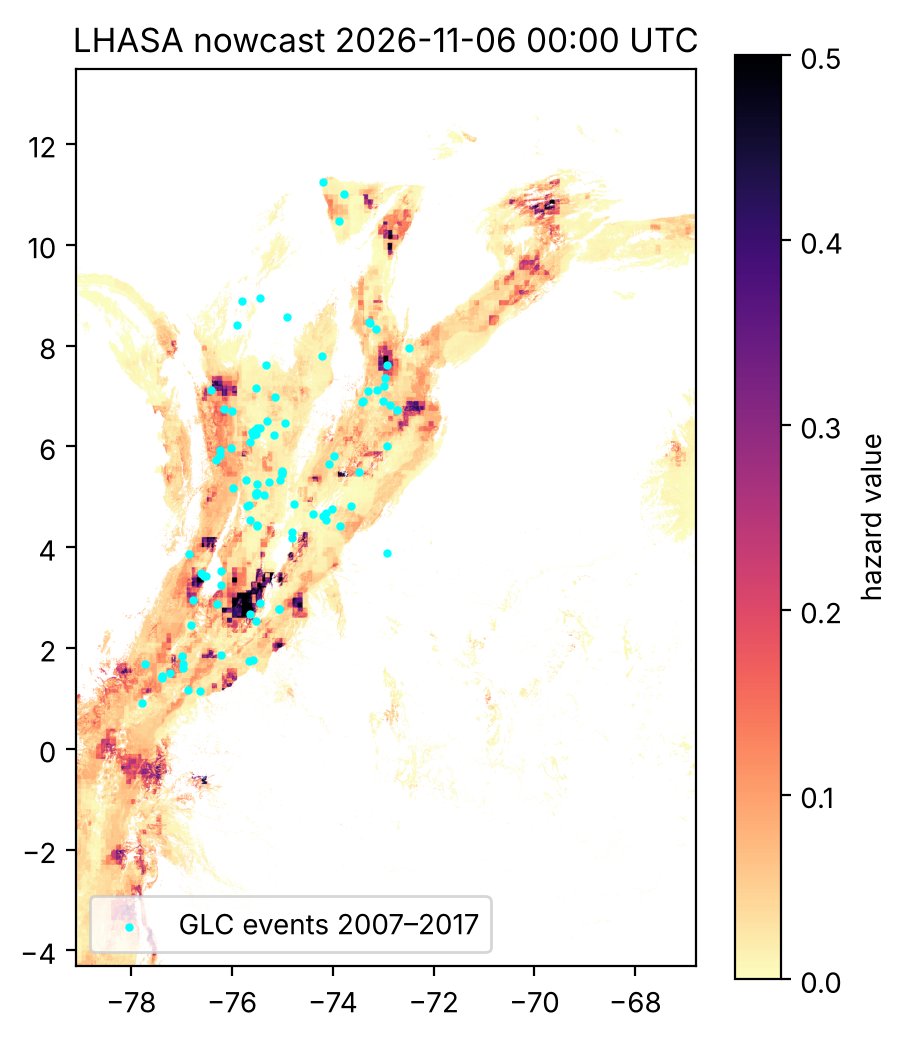

,city,req_lat,req_lon,lhasa_2026_11_06
0,Bogota,4.711,-74.072,NaN
1,Medellin,6.244,-75.581,0.0086
2,Manizales,5.070,-75.517,0.0260
3,Mocoa,1.152,-76.646,NaN
4,Cali,3.452,-76.532,NaN
5,Bucaramanga,7.119,-73.123,NaN
6,Pasto,1.214,-77.281,NaN
7,Ibague,4.438,-75.232,NaN
8,Popayan,2.444,-76.614,NaN
9,Pereira,4.813,-75.696,NaN


In [26]:
with rasterio.open(SAMPLES / "lhasa_colombia_20261106T0000.tif") as s:
    arr = s.read(1); ext = [s.bounds.left, s.bounds.right, s.bounds.bottom, s.bounds.top]
    vals_at_cities = [arr[s.index(lon, lat)] for lat, lon in zip(cities.req_lat, cities.req_lon)]
fig, ax = plt.subplots(figsize=(5, 6))
im = ax.imshow(arr, extent=ext, cmap="magma_r", vmin=0, vmax=0.5)
ax.scatter(co.longitude, co.latitude, s=4, c="cyan", label="GLC events 2007–2017")
ax.set_title("LHASA nowcast 2026-11-06 00:00 UTC"); ax.legend(loc="lower left"); plt.colorbar(im, label="hazard value")
plt.show()
cities.assign(lhasa_2026_11_06=np.round(vals_at_cities, 4))

In [27]:
masks = []
for fp in sorted(SAMPLES.glob("lhasa_colombia_*.tif")):
    with rasterio.open(fp) as s:
        masks.append(np.isnan(s.read(1)))
print("NaN mask identical on both days:", bool((masks[0] == masks[1]).all()))

NaN mask identical on both days: True


The NaN mask is identical on both days, so it is static (cells LHASA does not evaluate), not a rain signal.
Eight of the ten city centres fall on NaN cells (valley floors / urban flat terrain), so the indicator must
aggregate LHASA over a neighbourhood or region instead of reading the value at a point.

## 5. Data-quality findings (with example records)

In [28]:
ex = lambda i: glc.loc[glc.event_id == i, ["event_id", "event_date", "event_title", "country_name", "latitude", "longitude",
                                            "location_accuracy", "fatality_count"]]
print("1) Missing country for Colombian events (Mocoa, 2017). Date also differs from the documented disaster night (31 Mar–1 Apr 2017):")
display(ex(10790))
print("2) Time stored inside event_date, event_time 100 % empty, 50.1 % of events at 00:00 = unknown time, no time zone:")
display(glc.loc[glc.event_id.isin([562, 2784]), ["event_id", "event_date", "event_time"]])
print("3) Location accuracy is a text field with units and 'unknown' (cannot be used numerically as is):")
display(co[co.location_accuracy == "unknown"][["event_id", "event_title", "location_accuracy"]].head(3))
print("4) Probable duplicate records of the same landslide with conflicting fatalities:")
display(ex(3352)); display(ex(3353))
print("5) Coordinates snapped to the Open-Meteo grid (requested vs. returned cell):")
display(snap[["city", "req_lat", "req_lon", "grid_lat", "grid_lon", "offset_km"]].head(3))
print("6) Same field name, different meaning: in the forecast API `rain` excludes showers, in the archive it equals precipitation:")
print("    forecast hours where precipitation != rain:", int((p1.precipitation != p1.rain).sum()), "of", len(p1),
      "| totals (mm):", round(p1.precipitation.sum(), 1), "vs", round(p1.rain.sum(), 1),
      "| archive days where precipitation_sum != rain_sum:", int((hist.precipitation_sum != hist.rain_sum).sum()))
display(p1[(p1.city == "Manizales") & (p1.time.between("2026-11-06T06:00", "2026-11-06T08:00"))][["city", "time", "precipitation", "rain"]])
print("7) LHASA: declared nodata (-9999) never used; NaN instead; raster stored south-up (see Section 4).")
print("8) LHASA: irregular publication — gaps of several days and changing issue times:")
display(gaps.sort_values("missing_days", ascending=False).head(3))
print("9) LHASA has no value at the city centre for", int(np.isnan(vals_at_cities).sum()), "of 10 cities (static mask)")
print("10) Rainfall-triggered events with almost no rain in the reanalysis (7-day total < 5 mm):")
display(ante.nsmallest(3, "rain_7d")[["event_id", "event_date", "event_title", "landslide_trigger", "location_accuracy", "rain_7d", "snap_km"]])

1) Missing country for Colombian events (Mocoa, 2017). Date also differs from the documented disaster night (31 Mar–1 Apr 2017):


,event_id,event_date,event_title,country_name,latitude,longitude,location_accuracy,fatality_count
10190,10790,03/25/2017 05:32:00 PM,Deadly Mocoa Landslide,NaN,1.151898,-76.639923,1km,329.0


2) Time stored inside event_date, event_time 100 % empty, 50.1 % of events at 00:00 = unknown time, no time zone:


,event_id,event_date,event_time
1046,2784,12/05/2010 02:30:00 PM,NaN
5144,562,05/31/2008 12:00:00 AM,NaN


3) Location accuracy is a text field with units and 'unknown' (cannot be used numerically as is):


,event_id,event_title,location_accuracy
3,7402,bus route from Neiva to San Vicente,unknown
30,2739,road between Bucaramanga and Cucuta,unknown
34,2722,Bolivar province,unknown


... (7 outputs left out)

7) LHASA: declared nodata (-9999) never used; NaN instead; raster stored south-up (see Section 4).
8) LHASA: irregular publication — gaps of several days and changing issue times:


,from,to,missing_days
313,2025-11-23,2025-12-03,9
293,2025-10-29,2025-11-04,5
360,2026-01-19,2026-01-24,4


9) LHASA has no value at the city centre for 8 of 10 cities (static mask)
10) Rainfall-triggered events with almost no rain in the reanalysis (7-day total < 5 mm):


,event_id,event_date,event_title,landslide_trigger,location_accuracy,rain_7d,snap_km
78,4121,12/30/2011 12:00:00 AM,"Samaná, Caldas",downpour,25km,4.9,1.6
74,605,06/24/2008 12:00:00 AM,"Hacari, North Santander",downpour,5km,17.7,9.0
62,4637,11/28/2012 12:00:00 AM,"Teorama , Norte de Santander",rain,10km,18.5,11.7


## 6. Overlap: records that describe the same real-world event
**(a) Within the GLC** — candidate duplicates: events within 3 days and 30 km of each other in Colombia.

In [29]:
pairs = []
for i in range(len(co)):
    for j in range(i + 1, len(co)):
        dd = abs((co.event_dt[i].normalize() - co.event_dt[j].normalize()).days)  # calendar-day difference
        km = haversine_km(co.latitude[i], co.longitude[i], co.latitude[j], co.longitude[j])
        if dd <= 3 and km <= 30:
            pairs.append(dict(id_a=co.event_id[i], id_b=co.event_id[j], days=dd, km=round(km, 1),
                              title_a=co.event_title[i][:40], title_b=co.event_title[j][:40],
                              fatal_a=co.fatality_count[i], fatal_b=co.fatality_count[j],
                              acc_a=co.location_accuracy[i], acc_b=co.location_accuracy[j]))
pd.DataFrame(pairs)

,id_a,id_b,days,km,title_a,title_b,fatal_a,fatal_b,acc_a,acc_b
0,3353,3352,0,4.4,"San Antonio(?) de Chuza, El Tambo, Narin","El Tambo, Nariño",5.0,0.0,5km,5km
1,9226,9170,0,15.1,"road between Medellin and Quibdo, Choco",between Quibdó and Medellín in Chocó Dep,5.0,8.0,25km,25km
2,2331,2356,3,1.3,near Malaga,"near Malaga, Garcia Rovira locality, San",0.0,0.0,5km,5km
3,2736,2737,0,13.9,"San Daniel, Pensilvania municipality, Ca","El Aguacate(?), Marquetalia municipality",5.0,1.0,5km,25km
4,3359,3360,0,15.5,Manizales,"Road between Manizales and Bogota, near",0.0,20.0,10km,5km
5,3503,3500,2,26.9,"San Vicente de Chucuri, Santander depart","La Azufrada(?), road between Bucaramanga",1.0,2.0,5km,25km
6,2738,2737,0,24.6,"Montebonito(?), Marulanda municipality,","El Aguacate(?), Marquetalia municipality",2.0,1.0,25km,25km
7,4095,4091,2,29.7,San Lorenzo,"La cruz, Narino, Bogata",9.0,1.0,1km,10km


**(b) Across sources** — the same storm seen by the landslide inventory and by the rainfall reanalysis.
The pairs below link a GLC landslide to the Open-Meteo daily record of its grid cell on the event day.
What differs: position (point vs. ~0.1° grid cell centre), time (local date with unknown hour vs. daily
aggregate in America/Bogota), severity (fatalities/size class vs. millimetres), and identifier
(`event_id` vs. `latitude, longitude, date`).

In [30]:
top = ante.sort_values("rain_event_day", ascending=False).head(6)
top[["event_id", "event_date", "event_title", "latitude", "longitude", "grid_lat", "grid_lon", "snap_km",
     "rain_event_day", "rain_7d", "fatality_count"]]

,event_id,event_date,event_title,latitude,longitude,grid_lat,grid_lon,snap_km,rain_event_day,rain_7d,fatality_count
37,2507,09/27/2010 03:00:00 AM,"Morro Azul, near Anserma",5.1749,-75.9712,5.166960,-75.953766,2.1,74.9,176.6,4.0
100,2720,11/13/2010 12:00:00 AM,"just outside Quinchia(villa de los cerros) town, Risaral...",5.3391,-75.7311,5.307557,-75.781650,6.6,71.2,320.3,4.0
56,5957,03/13/2014 08:30:00 AM,"Palmira, Valle del Cauca",3.5181,-76.2244,3.550088,-76.215576,3.7,61.2,209.5,2.0
35,8908,04/12/2016 09:00:00 AM,"kilometer 6 of the road to the sea, near Cali",3.4856,-76.6104,3.479789,-76.663970,6.0,50.4,179.9,0.0
29,3311,03/28/2011 12:00:00 AM,"Avenida Centenario, western part of Manizales city",5.0569,-75.5271,5.096661,-75.519806,4.5,44.6,342.9,0.0
46,3499,05/16/2011 09:50:00 AM,"outskirts of Cali city, Valle de Cauca province",3.4677,-76.5908,3.479789,-76.591095,1.3,44.5,185.4,0.0


**(c) LHASA vs. GLC** — no temporal overlap: the GLC ends in September 2017 and the LHASA NRT archive
starts in January 2025. They can only be related spatially (the map above shows past events falling on the
cells LHASA flags), not as matching events. This is a limitation for validating the indicator.

## 7. Volume estimates for the full historical load

In [31]:
print("GLC: single file,", f"{glc_file.stat().st_size/1e6:.1f} MB,", len(glc), "rows; Colombia:", len(co))
cost = float(re.search(r"X-RateLimit-Cost: ([\d.]+)", open(SAMPLES / "openmeteo_historical_20261107_044802.headers").read()).group(1))
rule = 10 * 731 / 14 * 3 / 10   # locations x days/14 x variables/10
print(f"Open-Meteo cost of the historical sample: header = {cost:.2f}, rule = {rule:.2f}")

GLC: single file, 8.5 MB, 11033 rows; Colombia: 107
Open-Meteo cost of the historical sample: header = 156.64, rule = 156.64


The header confirms the weighting rule published by Open-Meteo:
**weight = locations × (days / 14) × (variables / 10)**. The free tier allows 10,000 per day
(5,000 per hour, 600 per minute).

In [32]:
days = (pd.Timestamp("2026-11-06") - pd.Timestamp("2007-01-01")).days + 1
with rasterio.open(SAMPLES / "lhasa_colombia_20261106T0000.tif") as s:
    finite = np.isfinite(s.read(1)); res = s.res[0]
rows = []
for cell in [0.25, 0.5]:
    k = int(round(cell / res)); H, W = finite.shape[0] // k * k, finite.shape[1] // k * k
    n = int((finite[:H, :W].reshape(H // k, k, W // k, k).mean(axis=(1, 3)) > 0.5).sum())
    for nvars in [1, 3]:
        w = n * days / 14 * nvars / 10
        rows.append(dict(grid_deg=cell, points=n, variables=nvars, days=days, daily_rows=n * days,
                         api_weight=round(w), days_of_free_quota=round(w / 10000, 1)))
pd.DataFrame(rows)

,grid_deg,points,variables,days,daily_rows,api_weight,days_of_free_quota
0,0.25,782,1,7250,5669500,40496,4.0
1,0.25,782,3,7250,5669500,121489,12.1
2,0.50,194,1,7250,1406500,10046,1.0
3,0.50,194,3,7250,1406500,30139,3.0


Points = grid cells inside the bounding box where LHASA evaluates hazard (more than half of the cell has
values); this includes some cells in neighbouring countries, so it is an upper bound for Colombia.
With one variable (`precipitation_sum`) a 0.25° grid for 2007–2026 needs about 4 days of free quota and a 0.5°
grid about one, so the bulk load is partitioned by point and year and spread over several runs.
LHASA: ~140 MB per global file, but ~1.5 MB per day for the Colombia window read with range requests.